First cell — Load ML datasets

In [1]:

# STEP 1: IMPORT LIBRARIES AND LOAD ML DATASETS

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

# Dataset directory
DATA_DIR = Path("../data/processed/ml_dataset_1")

# Load datasets
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

# Verify
print("TRAINING SHAPE:", X_train.shape)
print("TESTING SHAPE:", X_test.shape)

print("\nTRAIN LABELS:")
print(y_train.value_counts())

print("\nTEST LABELS:")
print(y_test.value_counts())

assert X_train.shape[1] == X_test.shape[1]
assert list(X_train.columns) == list(X_test.columns)
assert set(y_train.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

print("\nDATA LOADED AND VERIFIED SUCCESSFULLY")


TRAINING SHAPE: (7998, 637)
TESTING SHAPE: (2000, 637)

TRAIN LABELS:
label
1    4000
0    3998
Name: count, dtype: int64

TEST LABELS:
label
0    1000
1    1000
Name: count, dtype: int64

DATA LOADED AND VERIFIED SUCCESSFULLY


Next: Step 2 — Train and benchmark three models.

We will use a validation split from the training data. The final 2,000 test records will remain untouched until final evaluation.

In [3]:

# FIX: MAKE FEATURE NAMES XGBOOST-COMPATIBLE

import re

# Preserve original feature names for explainability
original_feature_names = X_train.columns.tolist()

def clean_feature_name(name):
    name = str(name)
    name = re.sub(r'[\[\]<>]', '_', name)
    return name

clean_names = [
    clean_feature_name(col) for col in X_train.columns
]

# Ensure unique names after cleaning
seen = {}
unique_names = []

for name in clean_names:
    count = seen.get(name, 0)
    unique_names.append(name if count == 0 else f"{name}_{count}")
    seen[name] = count + 1

X_train.columns = unique_names
X_test.columns = unique_names

print("Feature names sanitized.")
print("Total features:", len(unique_names))
print("Unique names:", len(set(unique_names)))
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Feature names sanitized.
Total features: 637
Unique names: 637
Train shape: (7998, 637)
Test shape: (2000, 637)


In [4]:

# STEP 2: MODEL TRAINING AND BENCHMARKING

import time
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Internal validation split
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )
}

# Add XGBoost if installed
try:
    from xgboost import XGBClassifier

    models["XGBoost"] = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("XGBoost not installed. Skipping for now.")

results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start = time.time()

    model.fit(X_fit, y_fit)

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    elapsed = time.time() - start

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1 Score": f1_score(y_val, predictions),
        "ROC AUC": roc_auc_score(y_val, probabilities),
        "Training Time (s)": round(elapsed, 2)
    })

    trained_models[name] = model

benchmark_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
)

print("\nMODEL BENCHMARK RESULTS")
display(benchmark_df)



Training Random Forest...

Training Extra Trees...

Training XGBoost...

MODEL BENCHMARK RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Training Time (s)
0,Random Forest,0.959375,0.976654,0.94125,0.958625,0.992701,0.81
1,Extra Trees,0.958125,0.976593,0.93875,0.957298,0.993086,0.87
2,XGBoost,0.953125,0.958281,0.94750,0.952860,0.991592,1.64



Random Forest
              precision    recall  f1-score   support

     Class 0     0.9433    0.9775    0.9601       800
     Class 1     0.9767    0.9413    0.9586       800

    accuracy                         0.9594      1600
   macro avg     0.9600    0.9594    0.9594      1600
weighted avg     0.9600    0.9594    0.9594      1600


Extra Trees
              precision    recall  f1-score   support

     Class 0     0.9410    0.9775    0.9589       800
     Class 1     0.9766    0.9387    0.9573       800

    accuracy                         0.9581      1600
   macro avg     0.9588    0.9581    0.9581      1600
weighted avg     0.9588    0.9581    0.9581      1600


XGBoost
              precision    recall  f1-score   support

     Class 0     0.9481    0.9587    0.9534       800
     Class 1     0.9583    0.9475    0.9529       800

    accuracy                         0.9531      1600
   macro avg     0.9532    0.9531    0.9531      1600
weighted avg     0.9532    0.9531    

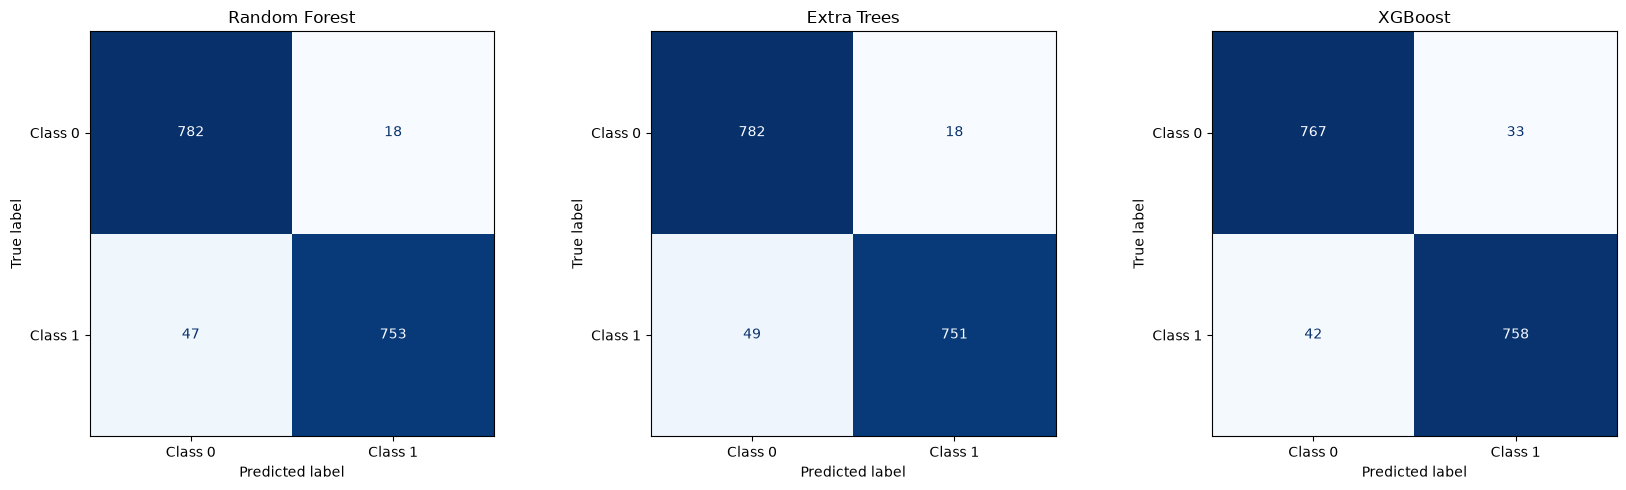

In [5]:

# STEP 3: DETAILED MODEL EVALUATION

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, model) in zip(axes, trained_models.items()):

    predictions = model.predict(X_val)

    cm = confusion_matrix(y_val, predictions)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Class 0", "Class 1"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print(classification_report(
        y_val,
        predictions,
        target_names=["Class 0", "Class 1"],
        digits=4
    ))

plt.tight_layout()
plt.show()



Random Forest - TOP 20 FEATURES


,Feature,Importance
46,header_coff_characteristics_DLL,0.054311
26,header_optional_image_base,0.045328
71,section_size_ratio_sum,0.037029
93,section_overlay_size,0.033392
74,section_size_ratio_min,0.032876
94,section_overlay_size_ratio,0.032866
73,section_size_ratio_max,0.028786
79,section_vsize_ratio_min,0.023891
95,section_overlay_entropy,0.023022
24,header_optional_address_of_entrypoint,0.021809


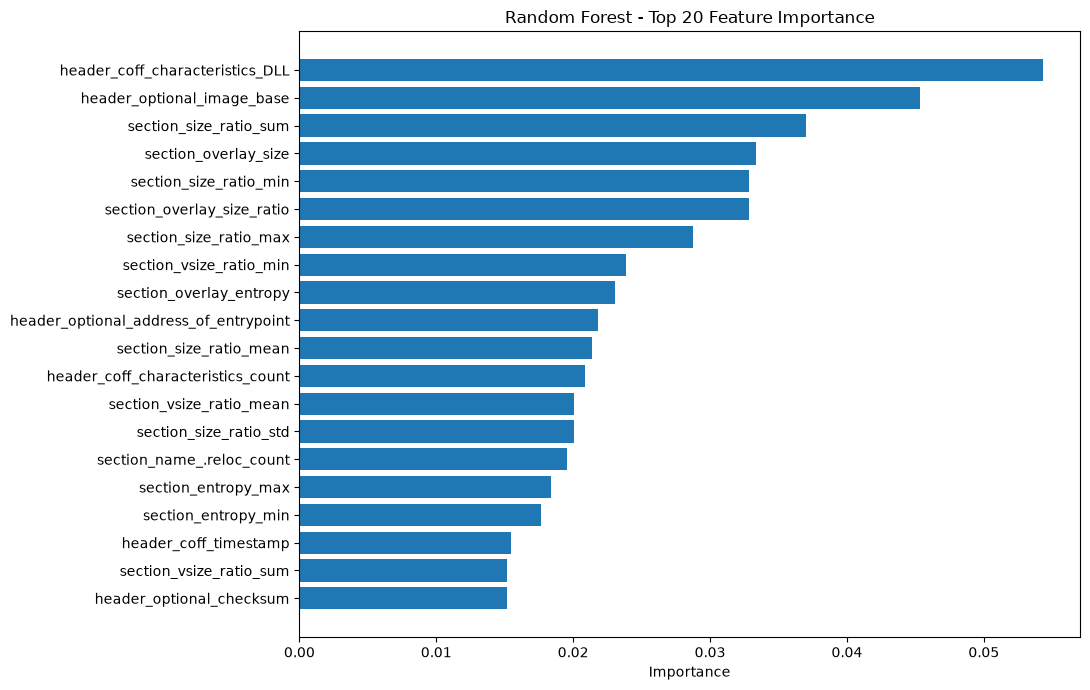


Extra Trees - TOP 20 FEATURES


,Feature,Importance
46,header_coff_characteristics_DLL,0.123007
94,section_overlay_size_ratio,0.068068
95,section_overlay_entropy,0.027500
5,header_coff_characteristics_count,0.027061
49,header_coff_characteristics_RELOCS_STRIPPED,0.021931
134,section_name_.buildid_count,0.016424
68,section_entropy_max,0.015320
79,section_vsize_ratio_min,0.015240
93,section_overlay_size,0.014753
67,section_entropy_mean,0.013665


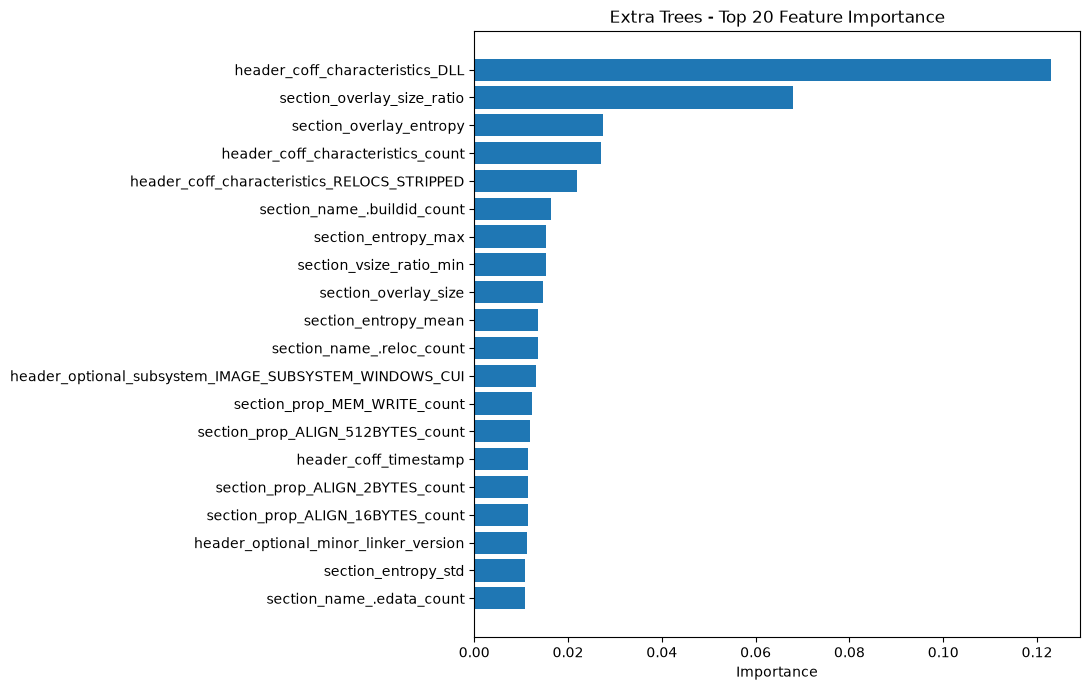


XGBoost - TOP 20 FEATURES


,Feature,Importance
46,header_coff_characteristics_DLL,0.239834
26,header_optional_image_base,0.068468
108,section_name_.crt_count,0.045008
99,section_name_.edata_count,0.027820
125,section_prop_ALIGN_512BYTES_count,0.026809
627,section_entry_.text,0.025259
48,header_coff_characteristics_DEBUG_STRIPPED,0.020603
81,section_prop_CNT_CODE_count,0.020007
49,header_coff_characteristics_RELOCS_STRIPPED,0.019420
128,section_name_/45_count,0.019239


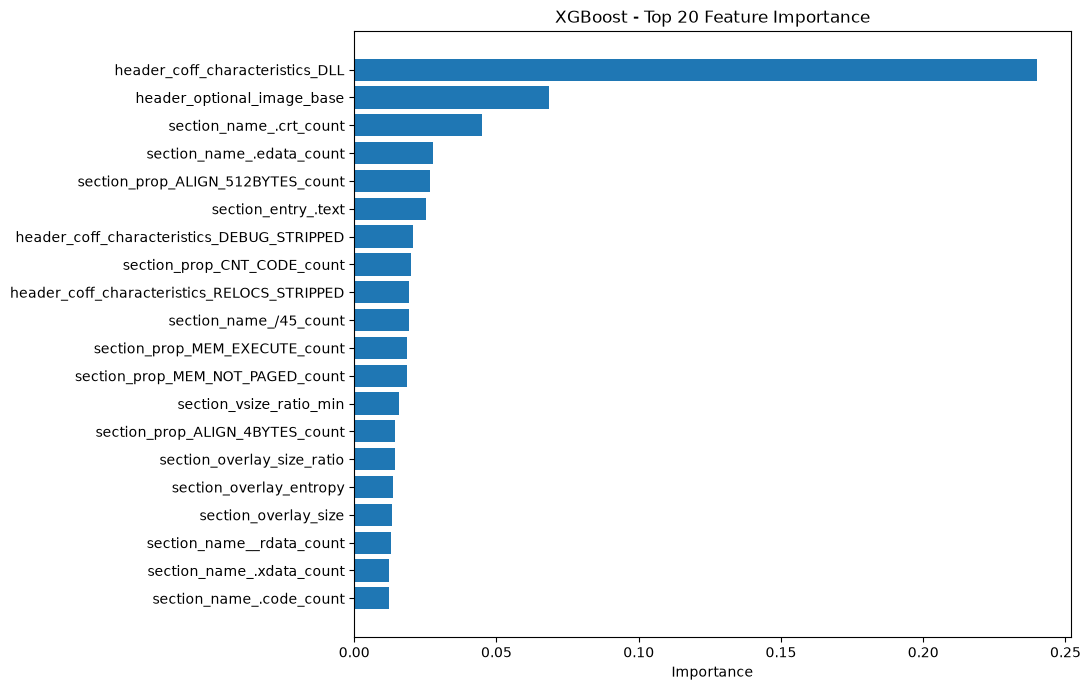


FEATURE IMPORTANCE ANALYSIS COMPLETED


In [6]:

# STEP 4: FEATURE IMPORTANCE ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt

for name, model in trained_models.items():

    importance_df = pd.DataFrame({
        "Feature": X_fit.columns,
        "Importance": model.feature_importances_
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    )

    print(f"\n{'='*60}")
    print(f"{name} - TOP 20 FEATURES")
    print("="*60)

    display(importance_df.head(20))

    plt.figure(figsize=(11, 7))

    top_features = importance_df.head(20).sort_values(
        "Importance"
    )

    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )

    plt.title(f"{name} - Top 20 Feature Importance")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

    importance_df.to_csv(
        f"{name.lower().replace(' ', '_')}_feature_importance.csv",
        index=False
    )

print("\nFEATURE IMPORTANCE ANALYSIS COMPLETED")


In [7]:
from lightgbm import LGBMClassifier

In [13]:
lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

In [16]:

# STEP 3A: SANITIZE FEATURE NAMES FOR LIGHTGBM

import re

# Preserve original feature names for later explainability
original_feature_names = X_fit.columns.tolist()

def sanitize_feature_names(columns):
    cleaned = []
    
    for i, name in enumerate(columns):
        name = str(name)
        
        # Replace unsupported characters
        name = re.sub(r'[^A-Za-z0-9_]', '_', name)
        
        # Ensure unique names
        cleaned.append(f"{name}_{i}")
    
    return cleaned

safe_feature_names = sanitize_feature_names(X_fit.columns)

X_fit_lgbm = X_fit.copy()
X_val_lgbm = X_val.copy()

X_fit_lgbm.columns = safe_feature_names
X_val_lgbm.columns = safe_feature_names

print("Original features:", len(original_feature_names))
print("Sanitized features:", len(safe_feature_names))
print("Unique names:", len(set(safe_feature_names)))
print("Feature names sanitized successfully.")


Original features: 637
Sanitized features: 637
Unique names: 637
Feature names sanitized successfully.


In [17]:

print("Training LightGBM...")

start = time.time()

lgbm.fit(X_fit_lgbm, y_fit)

predictions = lgbm.predict(X_val_lgbm)
probabilities = lgbm.predict_proba(X_val_lgbm)[:, 1]

training_time = time.time() - start

lgbm_results = {
    "Model": "LightGBM",
    "Accuracy": accuracy_score(y_val, predictions),
    "Precision": precision_score(y_val, predictions),
    "Recall": recall_score(y_val, predictions),
    "F1 Score": f1_score(y_val, predictions),
    "ROC AUC": roc_auc_score(y_val, probabilities),
    "Training Time (s)": round(training_time, 2)
}

print("\nLIGHTGBM RESULTS")

for metric, value in lgbm_results.items():
    print(f"{metric}: {value}")

print("\nLIGHTGBM TRAINING COMPLETED")


Training LightGBM...

LIGHTGBM RESULTS
Model: LightGBM
Accuracy: 0.960625
Precision: 0.9670468948035488
Recall: 0.95375
F1 Score: 0.960352422907489
ROC AUC: 0.9924046875
Training Time (s): 1.9

LIGHTGBM TRAINING COMPLETED


In [21]:

# STEP 5: LIGHTGBM HYPERPARAMETER OPTIMIZATION USING OPTUNA

import optuna
import lightgbm as lgb
import numpy as np
import pandas as pd
import time

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score

# Cross-validation configuration
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

def objective(trial):

    params = {
        "objective": "binary",
        "metric": "binary_logloss",
        "boosting_type": "gbdt",

        "n_estimators": trial.suggest_int(
            "n_estimators", 200, 800
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.15, log=True
        ),

        "num_leaves": trial.suggest_int(
            "num_leaves", 15, 63
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 3, 10
        ),

        "min_child_samples": trial.suggest_int(
            "min_child_samples", 10, 50
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.7, 1.0
        ),

        "subsample_freq": 1,

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-8, 10.0, log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-8, 10.0, log=True
        ),

        "min_split_gain": trial.suggest_float(
            "min_split_gain", 0.0, 0.2
        ),

        "random_state": 42,
        "n_jobs": 1,
        "verbosity": -1
    }

    fold_scores = []

    for train_idx, val_idx in cv.split(X_fit_lgbm, y_fit):

        X_train_fold = X_fit_lgbm.iloc[train_idx]
        X_val_fold = X_fit_lgbm.iloc[val_idx]

        y_train_fold = y_fit.iloc[train_idx]
        y_val_fold = y_fit.iloc[val_idx]

        model = lgb.LGBMClassifier(**params)

        model.fit(
            X_train_fold,
            y_train_fold,
            eval_set=[(X_val_fold, y_val_fold)],
            callbacks=[
                lgb.early_stopping(40, verbose=False)
            ]
        )

        predictions = model.predict(X_val_fold)

        score = f1_score(
            y_val_fold,
            predictions
        )

        fold_scores.append(score)

    return np.mean(fold_scores)


# Create Optuna study
study = optuna.create_study(
    direction="maximize",
    study_name="LightGBM_Malware_Optimization",
    sampler=optuna.samplers.TPESampler(seed=42)
)

print("STARTING OPTUNA OPTIMIZATION")

start_time = time.time()

study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=True
)

optimization_time = time.time() - start_time

print("\nOPTIMIZATION COMPLETED")

print("Best CV F1 Score:", study.best_value)

print("\nBEST HYPERPARAMETERS:")

for key, value in study.best_params.items():
    print(f"{key}: {value}")

print("\nOptimization time:", round(optimization_time, 2), "seconds")


/Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-11-10 17:50:24,830] A new study created in memory with name: LightGBM_Malware_Optimization


STARTING OPTUNA OPTIMIZATION


  0%|          | 0/30 [00:00<?, ?it/s]/Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 0. Best value: 0.949028:   3%|▎         | 1/30 [00

[I 2026-11-10 17:50:25,510] Trial 0 finished with value: 0.9490279753437648 and parameters: {'n_estimators': 425, 'learning_rate': 0.13125830316209655, 'num_leaves': 50, 'max_depth': 7, 'min_child_samples': 16, 'subsample': 0.7467983561008608, 'colsample_bytree': 0.7174250836504598, 'reg_alpha': 0.6245760287469887, 'reg_lambda': 0.002570603566117596, 'min_split_gain': 0.1416145155592091}. Best is trial 0 with value: 0.9490279753437648.


/Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 1. Best value: 0.94985:   7%|▋         | 2/30 [00:01<00:19,  1.45it/s] /Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-11-10 17:50:26,204] Trial 1 finished with value: 0.9498501785739606 and parameters: {'n_estimators': 212, 'learning_rate': 0.13826189316223855, 'num_leaves': 55, 'max_depth': 4, 'min_child_samples': 17, 'subsample': 0.7550213529560301, 'colsample_bytree': 0.7912726728878613, 'reg_alpha': 0.00052821153945323, 'reg_lambda': 7.71800699380605e-05, 'min_split_gain': 0.058245828039608386}. Best is trial 1 with value: 0.9498501785739606.


... (52 outputs left out)

/Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 5. Best value: 0.952854:  97%|█████████▋| 29/30 [00:36<00:01,  1.13s/it]/Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-11-10 17:51:01,125] Trial 28 finished with value: 0.9503227018495756 and parameters: {'n_estimators': 785, 'learning_rate': 0.053710455580347004, 'num_leaves': 59, 'max_depth': 7, 'min_child_samples': 13, 'subsample': 0.9331084110523005, 'colsample_bytree': 0.7602802592277578, 'reg_alpha': 6.151894393825347e-06, 'reg_lambda': 2.690803260957336e-08, 'min_split_gain': 0.028618240688483832}. Best is trial 5 with value: 0.9528542276710001.


/Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 5. Best value: 0.952854: 100%|██████████| 30/30 [00:37<00:00,  1.24s/it]

[I 2026-11-10 17:51:01,930] Trial 29 finished with value: 0.9493351816340364 and parameters: {'n_estimators': 720, 'learning_rate': 0.11337711658982562, 'num_leaves': 58, 'max_depth': 8, 'min_child_samples': 35, 'subsample': 0.9463826857769171, 'colsample_bytree': 0.7586287483786968, 'reg_alpha': 2.9137775378399552e-06, 'reg_lambda': 1.1045024467334041e-07, 'min_split_gain': 0.08523456297317464}. Best is trial 5 with value: 0.9528542276710001.

OPTIMIZATION COMPLETED
Best CV F1 Score: 0.9528542276710001

BEST HYPERPARAMETERS:
n_estimators: 782
learning_rate: 0.08158812228791566
num_leaves: 61
max_depth: 10
min_child_samples: 34
subsample: 0.976562270506935
colsample_bytree: 0.7265477506155759
reg_alpha: 5.805581976088804e-07
reg_lambda: 2.5529693461039728e-08
min_split_gain: 0.06506606615265287

Optimization time: 37.1 seconds


In [22]:

# STEP 6: TRAIN OPTIMIZED LIGHTGBM MODEL

best_params = study.best_params.copy()

best_params.update({
    "objective": "binary",
    "random_state": 42,
    "n_jobs": 1,
    "verbosity": -1
})

lgbm_optimized = lgb.LGBMClassifier(**best_params)

start = time.time()

lgbm_optimized.fit(X_fit_lgbm, y_fit)

optimization_training_time = time.time() - start

# Validation predictions
optimized_predictions = lgbm_optimized.predict(X_val_lgbm)

optimized_probabilities = (
    lgbm_optimized.predict_proba(X_val_lgbm)[:, 1]
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("OPTIMIZED LIGHTGBM RESULTS")

print("Accuracy:",
      accuracy_score(y_val, optimized_predictions))

print("Precision:",
      precision_score(y_val, optimized_predictions))

print("Recall:",
      recall_score(y_val, optimized_predictions))

print("F1 Score:",
      f1_score(y_val, optimized_predictions))

print("ROC AUC:",
      roc_auc_score(y_val, optimized_probabilities))

print("Training Time:",
      round(optimization_training_time, 2), "seconds")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_val,
    optimized_predictions
))

print("\nCONFUSION MATRIX")

print(confusion_matrix(
    y_val,
    optimized_predictions
))


OPTIMIZED LIGHTGBM RESULTS
Accuracy: 0.9625
Precision: 0.9695431472081218
Recall: 0.955
F1 Score: 0.9622166246851386
ROC AUC: 0.99245625
Training Time: 0.63 seconds

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.96      0.97      0.96       800
           1       0.97      0.95      0.96       800

    accuracy                           0.96      1600
   macro avg       0.96      0.96      0.96      1600
weighted avg       0.96      0.96      0.96      1600


CONFUSION MATRIX
[[776  24]
 [ 36 764]]


In [25]:

# STEP 7: SAVE OPTUNA RESULTS

import json
from pathlib import Path

# Define project output directory
PROJECT_ROOT = Path.cwd().parent

output_dir = (
    PROJECT_ROOT / "data" / "processed" / "ml_dataset_1"
)

# Create Optuna output directory
optimization_dir = output_dir / "optuna_results"
optimization_dir.mkdir(parents=True, exist_ok=True)

# Save best parameters
with open(
    optimization_dir / "lightgbm_best_params.json",
    "w"
) as file:
    json.dump(best_params, file, indent=4)

# Save all optimization trials
study.trials_dataframe().to_csv(
    optimization_dir / "optuna_trials.csv",
    index=False
)

# Save optimized model
lgbm_optimized.booster_.save_model(
    str(optimization_dir / "lightgbm_optimized.txt")
)

print("OPTUNA RESULTS SAVED")
print("Output directory:", optimization_dir.resolve())


OPTUNA RESULTS SAVED
Output directory: /Users/gouravsingh/Desktop/Ai-Ml-integrated-SOC-Platform/data/processed/ml_dataset_1/optuna_results


In [27]:

# STEP 8: BASELINE VS OPTIMIZED LIGHTGBM

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(model, X, y, name):

    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall": recall_score(y, pred),
        "F1 Score": f1_score(y, pred),
        "ROC AUC": roc_auc_score(y, prob)
    }


# Evaluate both models on exactly the same validation set
baseline_results = evaluate_model(
    lgbm,
    X_val_lgbm,
    y_val,
    "LightGBM Baseline"
)

optimized_results = evaluate_model(
    lgbm_optimized,
    X_val_lgbm,
    y_val,
    "LightGBM Optuna"
)

comparison_df = pd.DataFrame([
    baseline_results,
    optimized_results
])

print("LIGHTGBM HYPERPARAMETER OPTIMIZATION COMPARISON")

# Display comparison without Jinja2 dependency

comparison_display = comparison_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
]

for col in metric_columns:
    comparison_display[col] = (
        comparison_display[col] * 100
    ).round(2).astype(str) + "%"

display(comparison_display)

comparison_df.to_csv(
    optimization_dir / "lightgbm_comparison.csv",
    index=False
)

print("COMPARISON COMPLETED")


LIGHTGBM HYPERPARAMETER OPTIMIZATION COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,LightGBM Baseline,96.06%,96.7%,95.38%,96.04%,99.24%
1,LightGBM Optuna,96.25%,96.95%,95.5%,96.22%,99.25%


COMPARISON COMPLETED


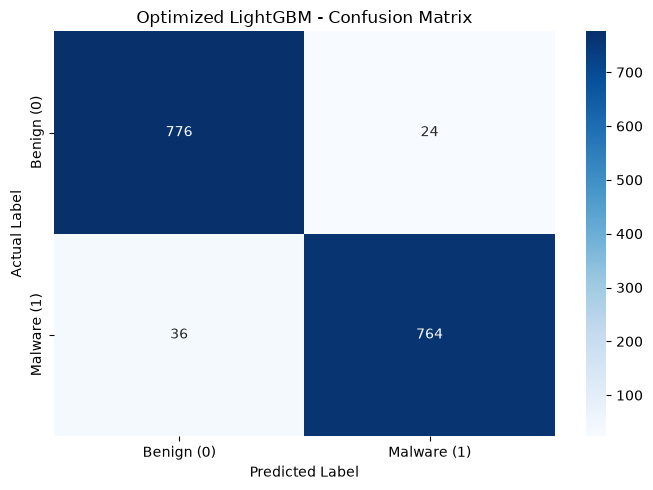

TN: 776
FP: 24
FN: 36
TP: 764


In [28]:

# STEP 9: OPTIMIZED LIGHTGBM CONFUSION MATRIX

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

optimized_predictions = lgbm_optimized.predict(X_val_lgbm)

cm = confusion_matrix(
    y_val,
    optimized_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign (0)", "Malware (1)"],
    yticklabels=["Benign (0)", "Malware (1)"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Optimized LightGBM - Confusion Matrix")

plt.tight_layout()
plt.show()

print("TN:", cm[0, 0])
print("FP:", cm[0, 1])
print("FN:", cm[1, 0])
print("TP:", cm[1, 1])


In [29]:

# STEP 10: COMPLETE MODEL BENCHMARK COMPARISON

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# All trained models
all_models = {
    "Random Forest": trained_models["Random Forest"],
    "Extra Trees": trained_models["Extra Trees"],
    "XGBoost": trained_models["XGBoost"],
    "LightGBM Baseline": lgbm,
    "LightGBM Optuna": lgbm_optimized
}

# Use the correct feature names for each model
model_inputs = {
    "Random Forest": X_val,
    "Extra Trees": X_val,
    "XGBoost": X_val,
    "LightGBM Baseline": X_val_lgbm,
    "LightGBM Optuna": X_val_lgbm
}

results = []

for name, model in all_models.items():

    X_input = model_inputs[name]

    predictions = model.predict(X_input)
    probabilities = model.predict_proba(X_input)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1 Score": f1_score(y_val, predictions),
        "ROC AUC": roc_auc_score(y_val, probabilities)
    })

# Create benchmark table
benchmark_all = pd.DataFrame(results)

benchmark_all = benchmark_all.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

# Percentage formatting
benchmark_display = benchmark_all.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
]

for col in metric_columns:
    benchmark_display[col] = (
        benchmark_display[col] * 100
    ).round(2).astype(str) + "%"

print("=" * 75)
print("COMPLETE MODEL BENCHMARK")
print("=" * 75)

display(benchmark_display)

# Identify leaders
print("\nMODEL LEADERS")

for metric in metric_columns:
    best = benchmark_all.loc[
        benchmark_all[metric].idxmax()
    ]

    print(
        f"{metric}: {best['Model']} "
        f"({best[metric] * 100:.2f}%)"
    )

# Save results
benchmark_all.to_csv(
    optimization_dir / "complete_model_benchmark.csv",
    index=False
)

print("\nBenchmark saved successfully.")


COMPLETE MODEL BENCHMARK


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,LightGBM Optuna,96.25%,96.95%,95.5%,96.22%,99.25%
1,LightGBM Baseline,96.06%,96.7%,95.38%,96.04%,99.24%
2,Random Forest,95.94%,97.67%,94.12%,95.86%,99.27%
3,Extra Trees,95.81%,97.66%,93.88%,95.73%,99.31%
4,XGBoost,95.31%,95.83%,94.75%,95.29%,99.16%



MODEL LEADERS
Accuracy: LightGBM Optuna (96.25%)
Precision: Random Forest (97.67%)
Recall: LightGBM Optuna (95.50%)
F1 Score: LightGBM Optuna (96.22%)
ROC AUC: Extra Trees (99.31%)

Benchmark saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,True Negatives,False Positives,False Negatives,True Positives
0,LightGBM Baseline,96.00%,96.84%,95.10%,95.96%,99.38%,969,31,49,951
1,Random Forest,95.85%,97.41%,94.20%,95.78%,99.31%,975,25,58,942
2,XGBoost,95.80%,96.54%,95.00%,95.77%,99.34%,966,34,50,950
3,LightGBM Optuna,95.55%,96.15%,94.90%,95.52%,99.38%,962,38,51,949
4,Extra Trees,95.55%,97.01%,94.00%,95.48%,99.23%,971,29,60,940


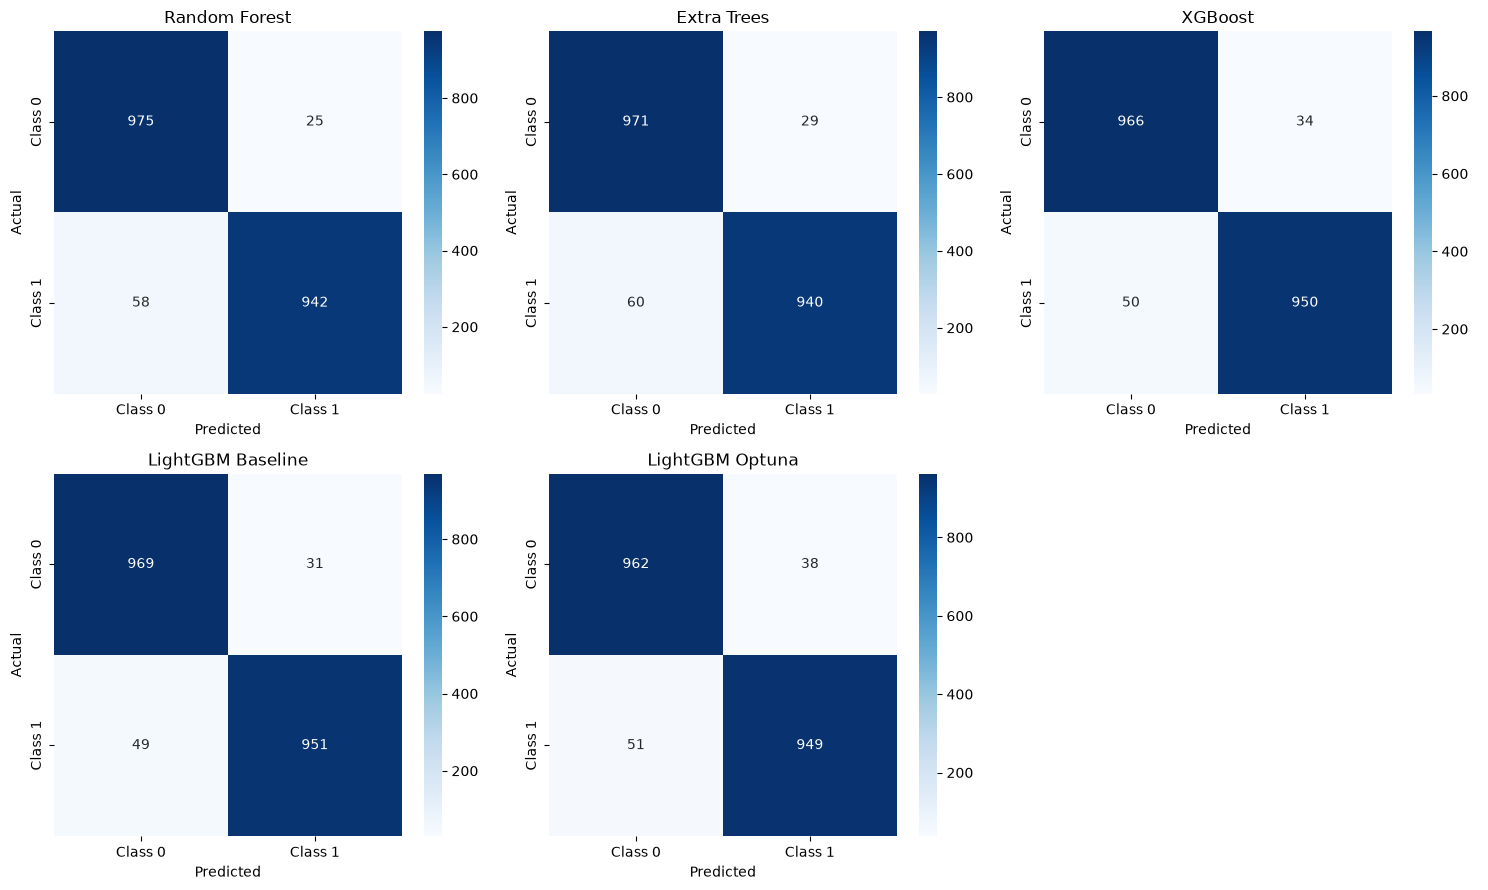


Random Forest
              precision    recall  f1-score   support

           0       0.94      0.97      0.96      1000
           1       0.97      0.94      0.96      1000

    accuracy                           0.96      2000
   macro avg       0.96      0.96      0.96      2000
weighted avg       0.96      0.96      0.96      2000


Extra Trees
              precision    recall  f1-score   support

           0       0.94      0.97      0.96      1000
           1       0.97      0.94      0.95      1000

    accuracy                           0.96      2000
   macro avg       0.96      0.96      0.96      2000
weighted avg       0.96      0.96      0.96      2000


XGBoost
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1000
           1       0.97      0.95      0.96      1000

    accuracy                           0.96      2000
   macro avg       0.96      0.96      0.96      2000
weighted avg       0.96      0.96    

In [31]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# 1. Prepare test data for LightGBM's sanitized feature names
X_test_lgbm = X_test.copy()

assert X_test_lgbm.shape[1] == X_fit_lgbm.shape[1], \
    "Feature count mismatch between test and LightGBM training data."

# Preserve the exact LightGBM feature names and column order
X_test_lgbm.columns = X_fit_lgbm.columns

# 2. Define all five trained models
all_models = {
    "Random Forest": trained_models["Random Forest"],
    "Extra Trees": trained_models["Extra Trees"],
    "XGBoost": trained_models["XGBoost"],
    "LightGBM Baseline": lgbm,
    "LightGBM Optuna": lgbm_optimized
}

test_inputs = {
    "Random Forest": X_test,
    "Extra Trees": X_test,
    "XGBoost": X_test,
    "LightGBM Baseline": X_test_lgbm,
    "LightGBM Optuna": X_test_lgbm
}

# 3. Evaluate models on untouched test data
y_true = np.asarray(y_test).ravel()

test_results = []
confusion_matrices = {}
classification_reports = {}

for name, model in all_models.items():

    X_input = test_inputs[name]

    y_pred = model.predict(X_input)
    y_prob = model.predict_proba(X_input)[:, 1]

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_true, y_prob),
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

    confusion_matrices[name] = cm
    classification_reports[name] = classification_report(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )

# 4. Consolidated comparison
test_benchmark = pd.DataFrame(test_results)
test_benchmark = test_benchmark.sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display(
    test_benchmark.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC AUC": "{:.2%}"
    })
)

# 5. Confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Class 0", "Class 1"],
        yticklabels=["Class 0", "Class 1"],
        ax=axes[i]
    )
    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

# 6. Detailed classification reports
for name, report in classification_reports.items():
    print(f"\n{'='*55}")
    print(name)
    print("="*55)
    print(report)

# 7. Save test evaluation results
test_benchmark.to_csv(
    optimization_dir / "independent_test_benchmark.csv",
    index=False
)

print("\nTest evaluation completed.")
print("Results saved to:", optimization_dir)


In [35]:

import pandas as pd

# Verify labels in the actual model-training dataset
print("TRAINING LABEL DISTRIBUTION")
print(y_train.value_counts().sort_index())

print("\nTEST LABEL DISTRIBUTION")
print(y_test.value_counts().sort_index())

# Documented mapping from project preprocessing report
label_mapping = {
    0: "Benign",
    1: "Malware"
}

print("\nDOCUMENTED LABEL MAPPING")
for label, meaning in label_mapping.items():
    print(f"Label {label} = {meaning}")

# Verify both classes exist
assert set(pd.Series(y_train).unique()) == {0, 1}
assert set(pd.Series(y_test).unique()) == {0, 1}

print("\nLabel verification completed.")


TRAINING LABEL DISTRIBUTION
label
0    3998
1    4000
Name: count, dtype: int64

TEST LABEL DISTRIBUTION
label
0    1000
1    1000
Name: count, dtype: int64

DOCUMENTED LABEL MAPPING
Label 0 = Benign
Label 1 = Malware

Label verification completed.


,Threshold,Accuracy,Precision,Recall,F1 Score,True Negatives,False Positives,False Negatives,True Positives
0,0.20,95.62%,94.19%,97.25%,95.69%,752,48,22,778
1,0.25,95.69%,94.85%,96.62%,95.73%,758,42,27,773
2,0.30,95.75%,95.07%,96.50%,95.78%,760,40,28,772
3,0.35,96.06%,95.66%,96.50%,96.08%,765,35,28,772
4,0.40,96.12%,96.24%,96.00%,96.12%,770,30,32,768
5,0.45,96.00%,96.58%,95.38%,95.97%,773,27,37,763
6,0.50,96.06%,96.70%,95.38%,96.04%,774,26,37,763
7,0.55,96.12%,96.95%,95.25%,96.09%,776,24,38,762
8,0.60,95.94%,96.93%,94.88%,95.89%,776,24,41,759
9,0.65,95.94%,97.42%,94.38%,95.87%,780,20,45,755


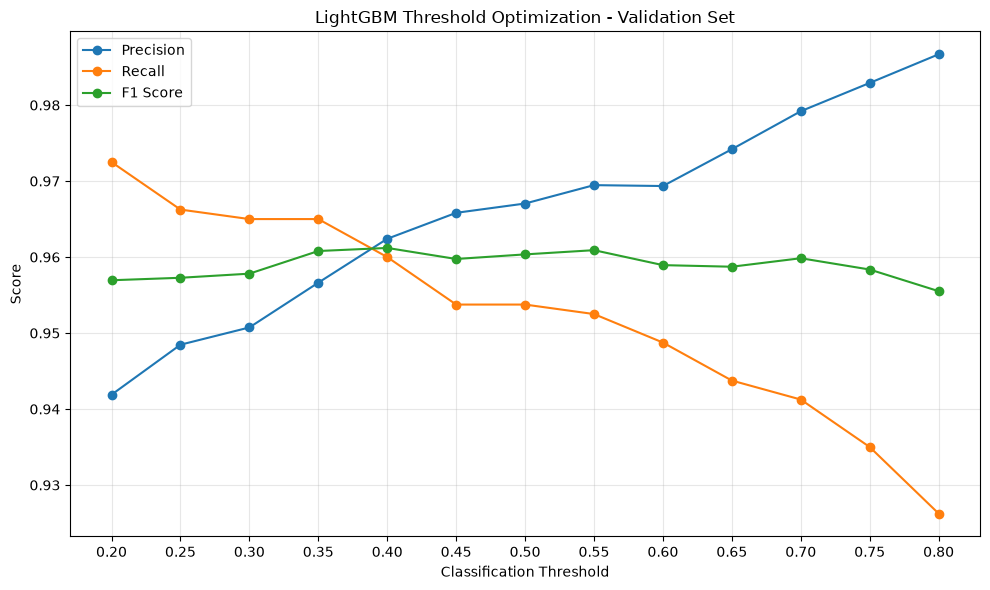

Threshold optimization completed.


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Malware is the positive class (label 1)
y_val_true = np.asarray(y_val).ravel()

# Get malware probabilities from baseline LightGBM
val_probabilities = lgbm.predict_proba(X_val_lgbm)[:, 1]

# Test multiple thresholds using validation data only
thresholds = np.arange(0.20, 0.81, 0.05)

threshold_results = []

for threshold in thresholds:

    y_pred = (val_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_true, y_pred, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_val_true, y_pred),
        "Precision": precision_score(
            y_val_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_true, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val_true, y_pred, zero_division=0
        ),
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

# Plot threshold impact
plt.figure(figsize=(10, 6))

for metric in ["Precision", "Recall", "F1 Score"]:
    plt.plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("LightGBM Threshold Optimization - Validation Set")
plt.xticks(thresholds)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Save validation threshold results
threshold_df.to_csv(
    optimization_dir / "threshold_optimization_validation.csv",
    index=False
)

print("Threshold optimization completed.")


,Threshold,Accuracy,Precision,Recall,F1 Score,ROC AUC,True Negatives,False Positives,False Negatives,True Positives
0,0.50,0.9600,0.968432,0.951,0.959637,0.993786,969,31,49,951
1,0.35,0.9615,0.958292,0.965,0.961634,0.993786,958,42,35,965


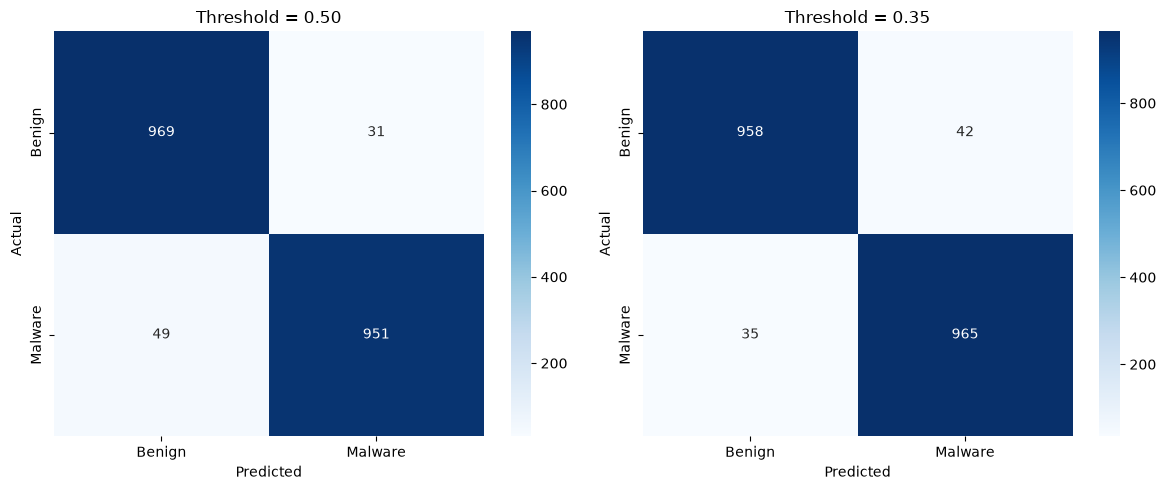

Independent threshold evaluation completed.


In [38]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# Selected using validation data only
selected_threshold = 0.35

# Get test probabilities from baseline LightGBM
test_probabilities = lgbm.predict_proba(X_test_lgbm)[:, 1]
y_test_true = np.asarray(y_test).ravel()

threshold_comparison = []
test_confusion_matrices = {}

for threshold in [0.50, selected_threshold]:

    y_pred = (test_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_true, y_pred, labels=[0, 1]
    ).ravel()

    threshold_comparison.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test_true, y_pred),
        "Precision": precision_score(y_test_true, y_pred),
        "Recall": recall_score(y_test_true, y_pred),
        "F1 Score": f1_score(y_test_true, y_pred),
        "ROC AUC": roc_auc_score(y_test_true, test_probabilities),
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

    test_confusion_matrices[threshold] = confusion_matrix(
        y_test_true, y_pred, labels=[0, 1]
    )

comparison_df = pd.DataFrame(threshold_comparison)

display(comparison_df)

# Visualize both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, threshold in zip(axes, [0.50, selected_threshold]):

    sns.heatmap(
        test_confusion_matrices[threshold],
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Benign", "Malware"],
        yticklabels=["Benign", "Malware"],
        ax=ax
    )

    ax.set_title(f"Threshold = {threshold:.2f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

# Save evaluation results and selected threshold
comparison_df.to_csv(
    optimization_dir / "final_threshold_test_comparison.csv",
    index=False
)

pd.DataFrame({
    "selected_threshold": [selected_threshold],
    "model": ["LightGBM Baseline"],
    "selection_basis": ["Validation set"]
}).to_csv(
    optimization_dir / "selected_model_threshold.csv",
    index=False
)

print("Independent threshold evaluation completed.")


### 3 Final model decision
LightGBM Baseline
- Classification threshold: 0.35
- Test accuracy: 96.15%
- Test precision: 95.83%
- Test recall: 96.50%
- Test F1: 96.16%
- False negatives: 35

In [ ]:
# Create final model directory
PROJECT_ROOT = Path.cwd().parent

final_dir = PROJECT_ROOT / "models" / "dataset_1"
final_dir.mkdir(parents=True, exist_ok=True)

# Selected configuration
selected_threshold = 0.35

# 1. Save trained LightGBM model
joblib.dump(
    lgbm,
    final_dir / "lightgbm_baseline.pkl"
)

# 2. Save exact feature names and order
feature_names = list(X_fit_lgbm.columns)

with open(final_dir / "feature_names.json", "w") as f:
    json.dump(feature_names, f, indent=4)

# 3. Save model configuration
model_config = {
    "model_name": "LightGBM Baseline",
    "dataset": "Dataset 1 - Windows PE",
    "target_mapping": {
        "0": "Benign",
        "1": "Malware"
    },
    "classification_threshold": selected_threshold,
    "positive_class": 1,
    "number_of_features": len(feature_names),
    "test_accuracy": 0.9615,
    "test_precision": 0.9583,
    "test_recall": 0.9650,
    "test_f1_score": 0.9616,
    "test_false_positives": 42,
    "test_false_negatives": 35
}

with open(final_dir / "model_config.json", "w") as f:
    json.dump(model_config, f, indent=4)

# 4. Save test evaluation
comparison_df.to_csv(
    final_dir / "threshold_test_evaluation.csv",
    index=False
)

# 5. Verify saved artifacts
print("FINAL MODEL ARTIFACTS")
for file in sorted(final_dir.iterdir()):
    print("-", file.name)

print("\nFeature count:", len(feature_names))
print("Selected threshold:", selected_threshold)
print("\nModel artifacts saved successfully.")


FINAL MODEL ARTIFACTS
- feature_names.json
- lightgbm_baseline.pkl
- model_config.json
- threshold_test_evaluation.csv

Feature count: 637
Selected threshold: 0.35

Model artifacts saved successfully.


In [40]:
# Locate saved artifacts
PROJECT_ROOT = Path.cwd().parent
final_dir = PROJECT_ROOT / "models" / "dataset_1"

model_path = final_dir / "lightgbm_baseline.pkl"
features_path = final_dir / "feature_names.json"
config_path = final_dir / "model_config.json"

# Load artifacts
loaded_model = joblib.load(model_path)

with open(features_path, "r") as f:
    saved_features = json.load(f)

with open(config_path, "r") as f:
    saved_config = json.load(f)

threshold = saved_config["classification_threshold"]

# Prepare one previously unseen test sample
sample = X_test_lgbm.iloc[[0]].copy()
sample = sample[saved_features]

# Predict
malware_probability = loaded_model.predict_proba(sample)[0, 1]

prediction = (
    "Malware"
    if malware_probability >= threshold
    else "Benign"
)

# Display result
print("MODEL:", saved_config["model_name"])
print("FEATURES:", len(saved_features))
print("THRESHOLD:", threshold)
print("MALWARE PROBABILITY:", round(malware_probability, 4))
print("PREDICTION:", prediction)
print("ACTUAL LABEL:", int(np.asarray(y_test).ravel()[0]))
print("\nSaved model inference test completed.")


MODEL: LightGBM Baseline
FEATURES: 637
THRESHOLD: 0.35
MALWARE PROBABILITY: 0.0001
PREDICTION: Benign
ACTUAL LABEL: 0

Saved model inference test completed.
